**bold text**# Predictive Maintenance — Machine Health & Failure Analysis

**Dataset:** AI4I 2020 Predictive Maintenance Dataset.

**Project goal:** Analyze industrial machine sensor readings to understand machine health,
identify patterns associated with failures, investigate unusual operating conditions,
and build a simple binary classification model to predict whether a machine failure
is likely.



## 1. Business Context and Questions

### Business context

Unexpected machine failures can interrupt production, increase maintenance costs,
and reduce equipment availability. Instead of waiting for a failure to happen,
the objective is to use historical operating data to understand which conditions
are associated with failures and whether current sensor readings can provide an
early warning.

### Analytical objective

Turn raw machine observations into decision-ready insight about:

- **Machine health** — which operating conditions are associated with failures?
- **Sensors** — which measurements change when failure risk is higher?
- **Machine types** — do different machine/product types show different failure rates?
- **Operating conditions** — do temperature, torque, speed, or tool wear matter?
- **Failure modes** — what kinds of failures occur most often?
- **Prediction** — can we classify an observation as failure vs. no failure?



### Important analytical caution

The dataset contains columns such as `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` that describe
specific failure modes. These columns should **not** be used as input features when
predicting `Machine failure`, because they are direct failure indicators and would
create target leakage.

Our prediction features will therefore focus on machine characteristics and sensor
measurements available before the failure label.

In [1]:
import pandas as pd
import numpy as np
import missingno
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
import joblib

In [2]:
DATA_PATH = "ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.tail(50)

Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9950,9951,L57130,L,298.1,307.8,1413,54.1,113,0,0,0,0,0,0
9951,9952,L57131,L,298.2,307.8,1355,59.4,115,0,0,0,0,0,0
9952,9953,L57132,L,298.2,307.8,1429,46.9,117,0,0,0,0,0,0
9953,9954,L57133,L,298.1,307.8,1565,35.3,119,0,0,0,0,0,0
9954,9955,M24814,M,298.1,307.9,1446,42.8,121,0,0,0,0,0,0
9955,9956,M24815,M,298.2,307.9,1462,38.8,124,0,0,0,0,0,0
9956,9957,M24816,M,298.2,307.8,1578,34.5,127,0,0,0,0,0,0
9957,9958,L57137,L,298.1,307.8,1606,33.0,130,0,0,0,0,0,0
9958,9959,M24818,M,298.1,307.8,1525,35.9,132,0,0,0,0,0,0
9959,9960,L57139,L,298.1,307.8,1379,49.1,135,0,0,0,0,0,0


## 2. Data Understanding



In [3]:
print(df.columns)
print(df.dtypes)
df.info()

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='str')
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int6

In [4]:
df.nunique()

UDI                        10000
Product ID                 10000
Type                           3
Air temperature [K]           93
Process temperature [K]       82
Rotational speed [rpm]       941
Torque [Nm]                  577
Tool wear [min]              246
Machine failure                2
TWF                            2
HDF                            2
PWF                            2
OSF                            2
RNF                            2
dtype: int64

In [5]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [6]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

<Axes: >

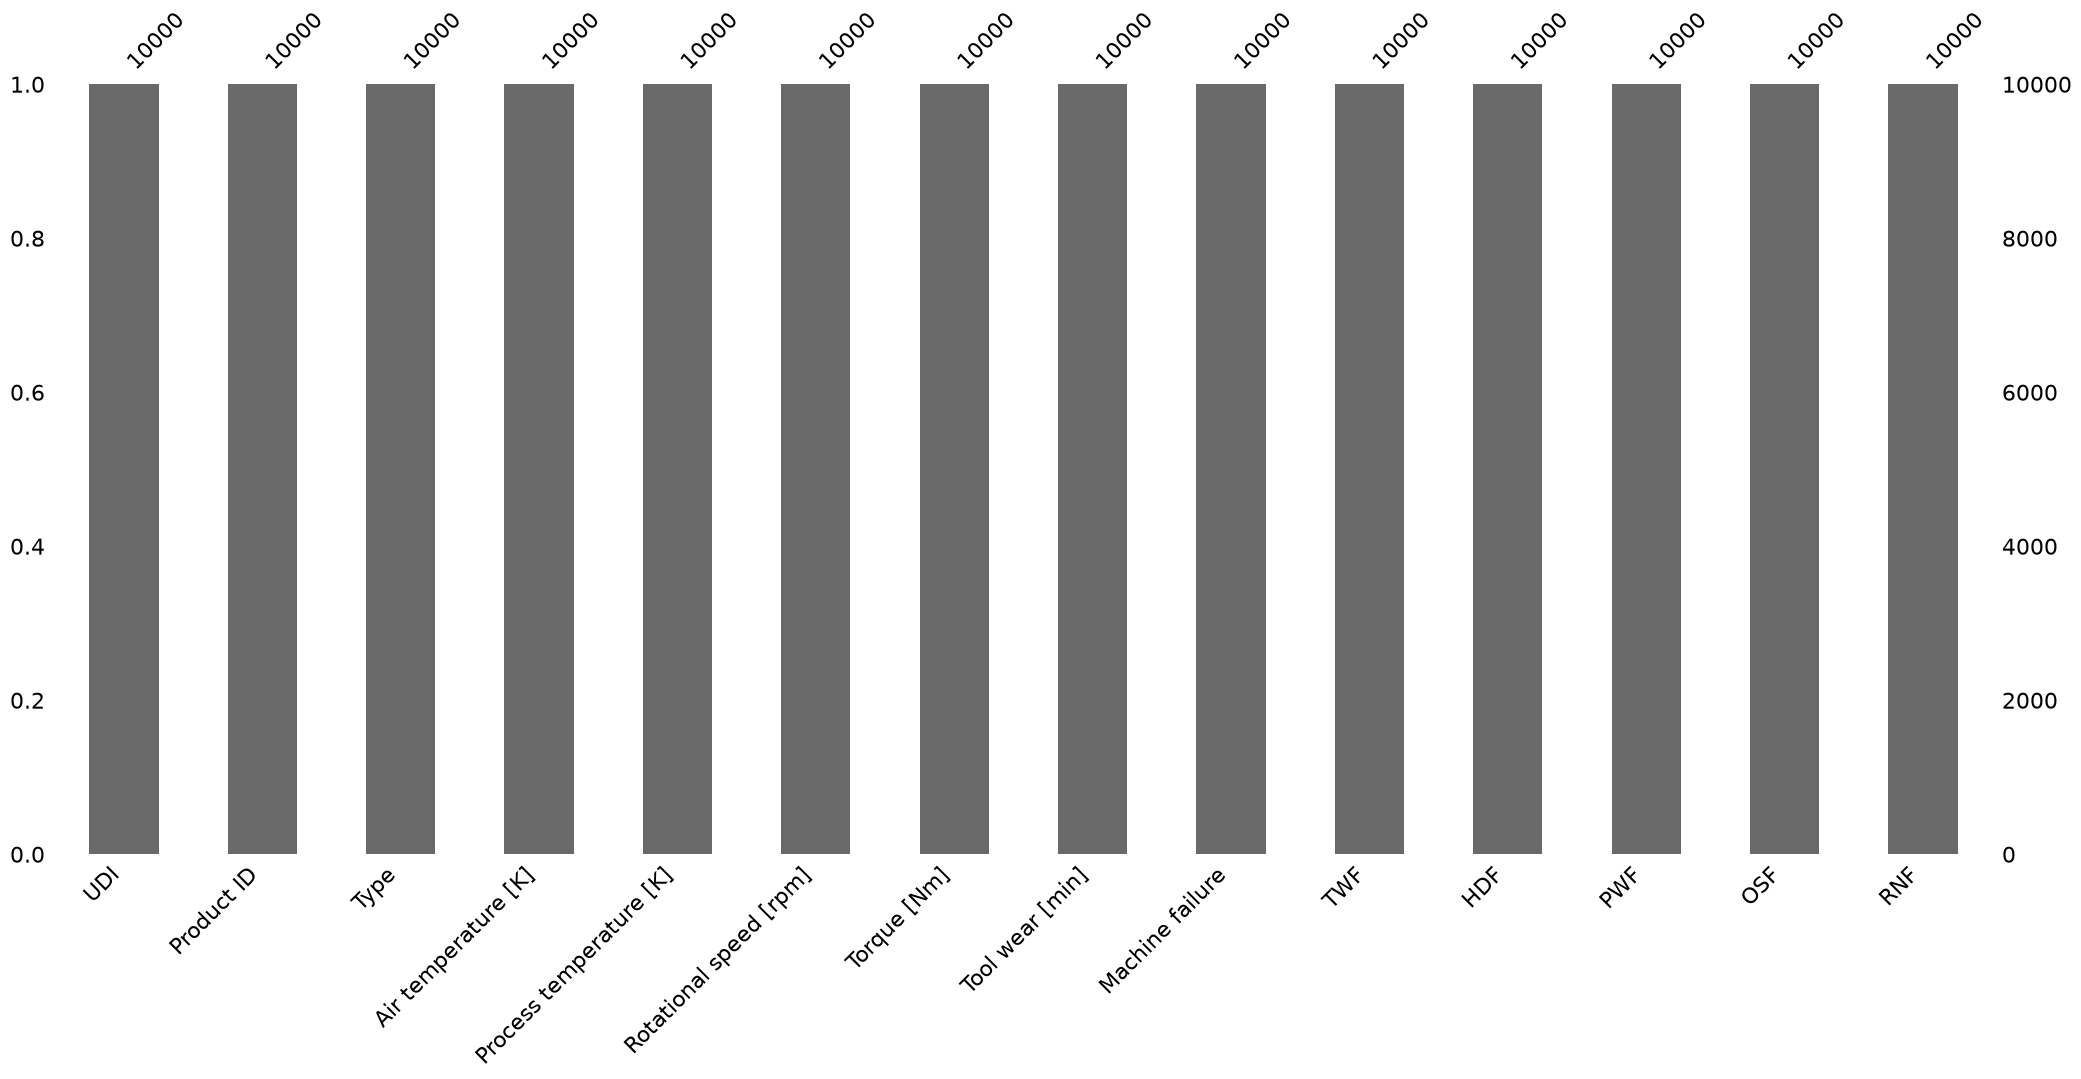

In [7]:
missingno.bar(df)

## 3. Data Quality



In [8]:
df.info()
print("Shape", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [9]:
print(df.isnull().sum())
print("Total missing values", df.isnull().sum().sum())

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64
Total missing values 0


In [10]:
print("Duplicated rows", df.duplicated().sum())
print("Duplicated Product ID", df["Product ID"].duplicated().sum())

Duplicated rows 0
Duplicated Product ID 0


In [11]:
print(df["Type"].value_counts())

print("Unique Unique Identifier", df["UDI"].is_unique)
print("Unique Product ID", df["Product ID"].is_unique)

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64
Unique Unique Identifier True
Unique Product ID True


In [12]:
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

print(df[num_cols].describe())

print(df["Machine failure"].value_counts())
print(df["Machine failure"].value_counts(normalize=True) * 100)

       Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
count         10000.000000             10000.000000            10000.000000   
mean            300.004930               310.005560             1538.776100   
std               2.000259                 1.483734              179.284096   
min             295.300000               305.700000             1168.000000   
25%             298.300000               308.800000             1423.000000   
50%             300.100000               310.100000             1503.000000   
75%             301.500000               311.100000             1612.000000   
max             304.500000               313.800000             2886.000000   

        Torque [Nm]  Tool wear [min]  
count  10000.000000     10000.000000  
mean      39.986910       107.951000  
std        9.968934        63.654147  
min        3.800000         0.000000  
25%       33.200000        53.000000  
50%       40.100000       108.000000  
75%       46.80

## 4. Exploratory Data Analysis

All Machine :  10000
No Failure Machine :  9661
Failure Machine:  339


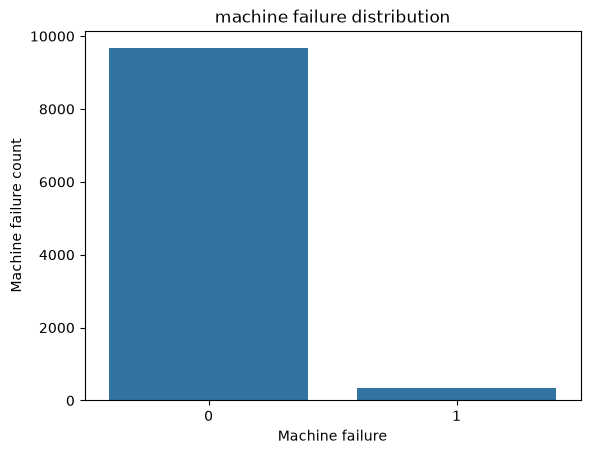

In [13]:
print("All Machine : ", df["UDI"].count())
print("No Failure Machine : " , df["UDI"].count()-(df["Machine failure"]==1).sum())
print("Failure Machine: ", (df["Machine failure"]==1).sum())
sns.countplot(data=df, x="Machine failure")
plt.title("machine failure distribution")
plt.xlabel("Machine failure")
plt.ylabel("Machine failure count")
plt.show()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64


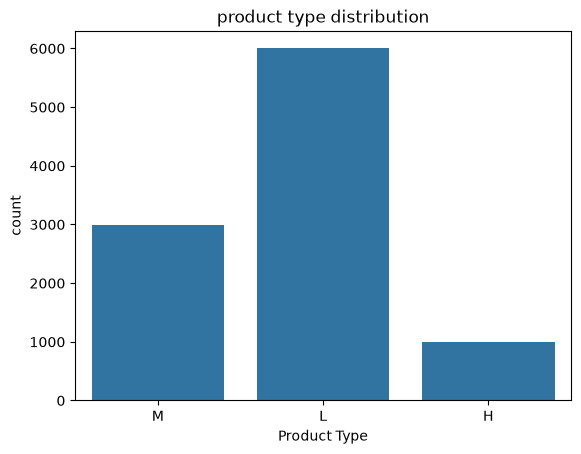

In [14]:
print(df["Type"].value_counts())
sns.countplot(data=df , x="Type")
plt.title("product type distribution")
plt.xlabel("Product Type")
plt.ylabel("count")
plt.show()

Type
H    2.09
L    3.92
M    2.77
Name: Machine failure, dtype: float64


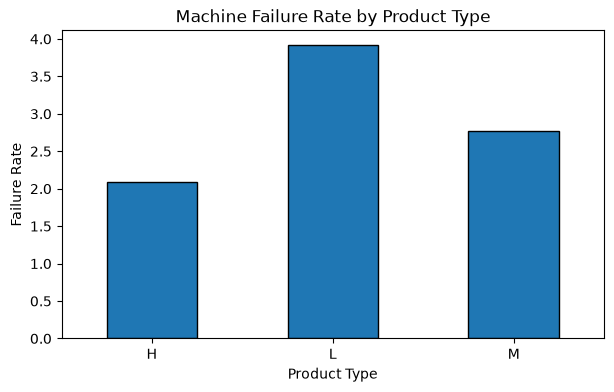

In [15]:
failure_by_type = df.groupby("Type")["Machine failure"].mean() * 100
print(failure_by_type.round(2))
failure_by_type.plot(
    kind="bar",
    figsize=(7, 4),
    edgecolor="black"
    )
plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate")
plt.xticks(rotation=0)
plt.show()

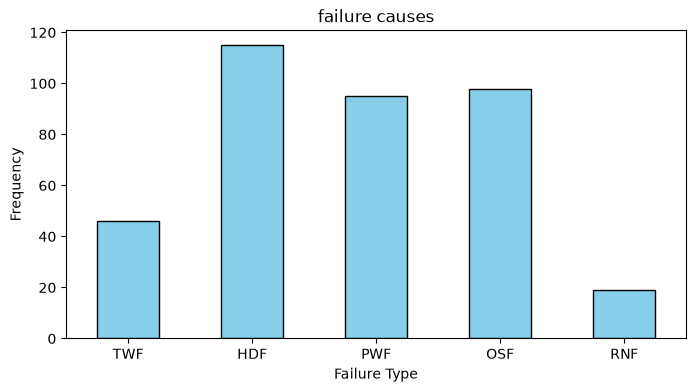

In [16]:
failure_cols=['TWF','HDF','PWF','OSF','RNF']
failure_sum=df[failure_cols].sum()
plt.figure(figsize=(8,4))
failure_sum.plot(kind='bar',color='skyblue',edgecolor='black')
plt.title("failure causes")
plt.xlabel("Failure Type")
plt.ylabel("Frequency")
plt.xticks(rotation=0)
plt.show()

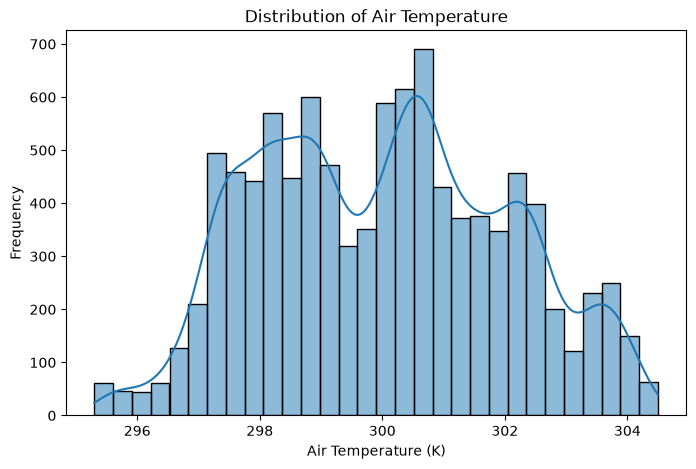

In [17]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Air temperature [K]",
    bins=30,
    kde=True)

plt.title("Distribution of Air Temperature")
plt.xlabel("Air Temperature (K)")
plt.ylabel("Frequency")
plt.show()

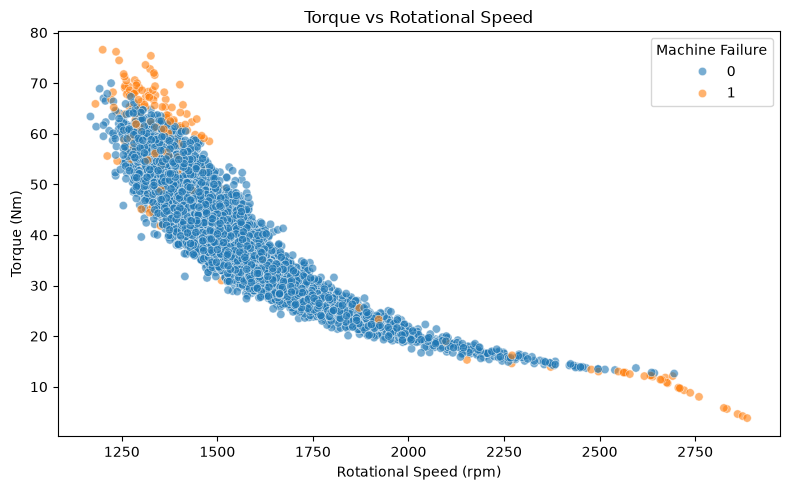

In [18]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Rotational speed [rpm]",
    y="Torque [Nm]",
    hue="Machine failure",
    alpha=0.6)

plt.title("Torque vs Rotational Speed")
plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.legend(title="Machine Failure")
plt.tight_layout()
plt.show()

## 5. Feature Engineering


In [19]:
df_fe = df.copy()

df_fe = df_fe.drop(columns=['UDI', 'Product ID'])

df_fe['Temp_Diff'] = df_fe['Process temperature [K]'] - df_fe['Air temperature [K]']
df_fe['Power'] = df_fe['Rotational speed [rpm]'] * df_fe['Torque [Nm]']
df_fe['Wear_Torque_Ratio'] = df_fe['Tool wear [min]'] * df_fe['Torque [Nm]']
df_fe['Wear_Speed_Interaction'] = df_fe['Tool wear [min]'] * df_fe['Rotational speed [rpm]']

type_mapping = {'L': 0, 'M': 1, 'H': 2}
df_fe['Type'] = df_fe['Type'].map(type_mapping)

In [20]:
features_to_scale = ['Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]','Tool wear [min]','Temp_Diff','Power','Wear_Torque_Ratio','Wear_Speed_Interaction']

scaler = StandardScaler()
df_fe[features_to_scale] = scaler.fit_transform(df_fe[features_to_scale])

df_fe.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Temp_Diff,Power,Wear_Torque_Ratio,Wear_Speed_Interaction
0,1,-0.952389,-0.947360,0.068185,0.282200,-1.695984,0,0,0,0,0,0,0.498849,0.629443,-1.526544,-1.651974
1,0,-0.902393,-0.879959,-0.729472,0.633308,-1.648852,0,0,0,0,0,0,0.498849,0.512456,-1.477401,-1.609967
2,0,-0.952389,-1.014761,-0.227450,0.944290,-1.617430,0,0,0,0,0,0,0.398954,1.376889,-1.439155,-1.577488
3,0,-0.902393,-0.947360,-0.590021,-0.048845,-1.586009,0,0,0,0,0,0,0.398954,-0.330009,-1.428717,-1.552218
4,0,-0.902393,-0.879959,-0.729472,0.001313,-1.554588,0,0,0,0,0,0,0.498849,-0.357824,-1.399175,-1.525954


## 6. Relationships Between Variables

Correlation does not prove causation, but it can help us identify relationships
worth investigating.

In [21]:
numeric = df.loc[:, ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]',
                     'Torque [Nm]', 'Tool wear [min]', 'Machine failure']]
cor = numeric.corr()
cor

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
Machine failure,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


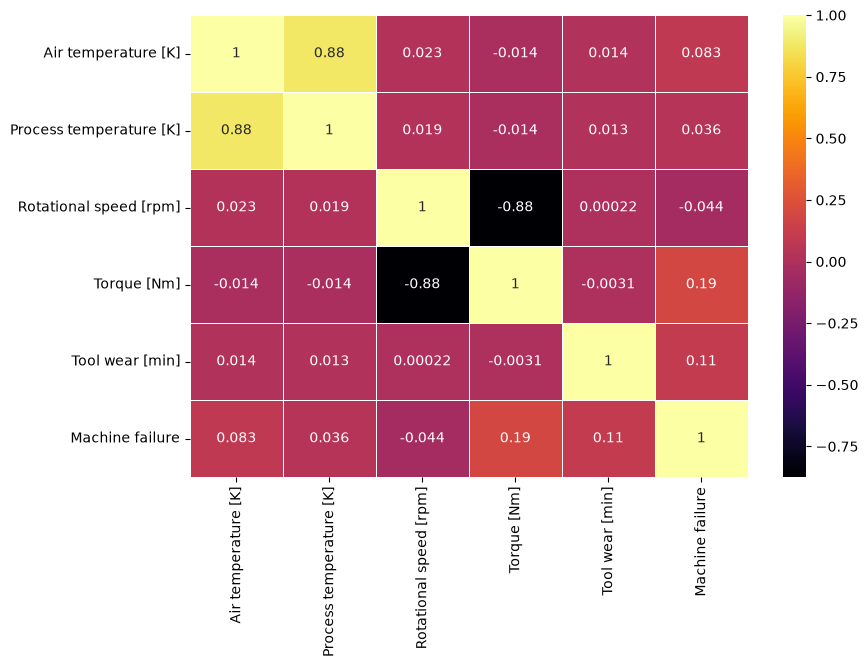

In [22]:
plt.figure(figsize=(9, 6))
sns.heatmap(cor, annot=True, linewidths=0.5, cmap='inferno')
plt.show()

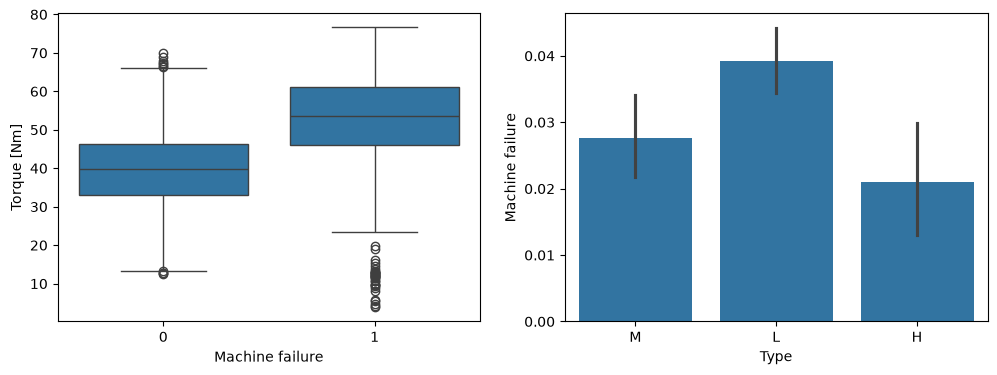

In [23]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(data=df, x='Machine failure', y='Torque [Nm]')
plt.subplot(1, 2, 2)
sns.barplot(data=df, x='Type', y='Machine failure')
plt.show()

### Failure-mode analysis

The dataset contains multiple failure-mode indicators. These are not used as
predictive features, but they are useful for answering a descriptive question:

**What kinds of failures are most common?**

In [24]:
failure_modes = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

failure_counts = df[failure_modes].sum().sort_values(ascending=False)
print(failure_counts)

print("Percentage of failed observations:\n")
print((failure_counts / df['Machine failure'].sum() * 100).round(1))

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64
Percentage of failed observations:

HDF    33.9
OSF    28.9
PWF    28.0
TWF    13.6
RNF     5.6
dtype: float64


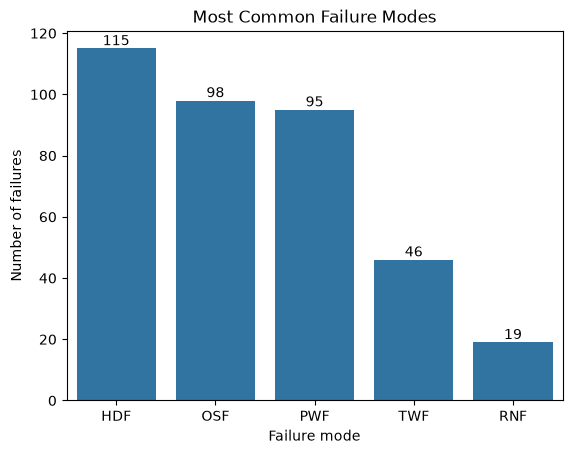

In [25]:
ax = sns.barplot(x=failure_counts.index, y=failure_counts.values)
for i in ax.containers: ax.bar_label(i, fmt='%.f')
plt.title("Most Common Failure Modes")
plt.xlabel("Failure mode")
plt.ylabel("Number of failures")
plt.show()

## 7. Visualization

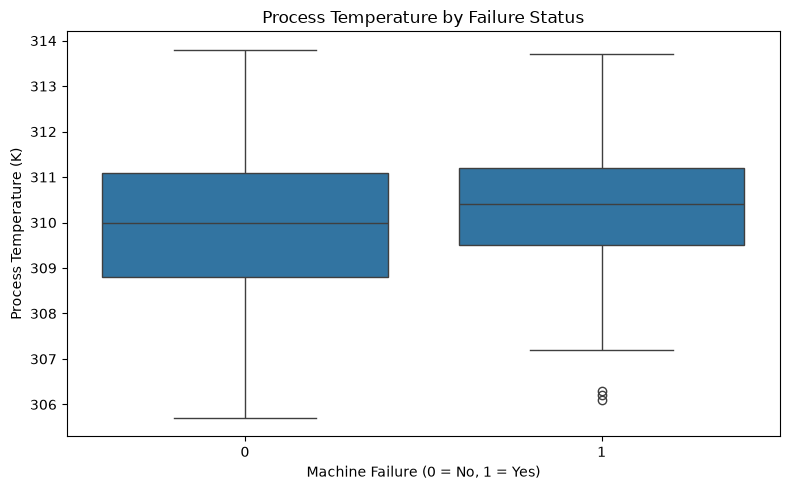

In [26]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df,x="Machine failure",y="Process temperature [K]")

plt.title("Process Temperature by Failure Status")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Process Temperature (K)")
plt.tight_layout()
plt.show()

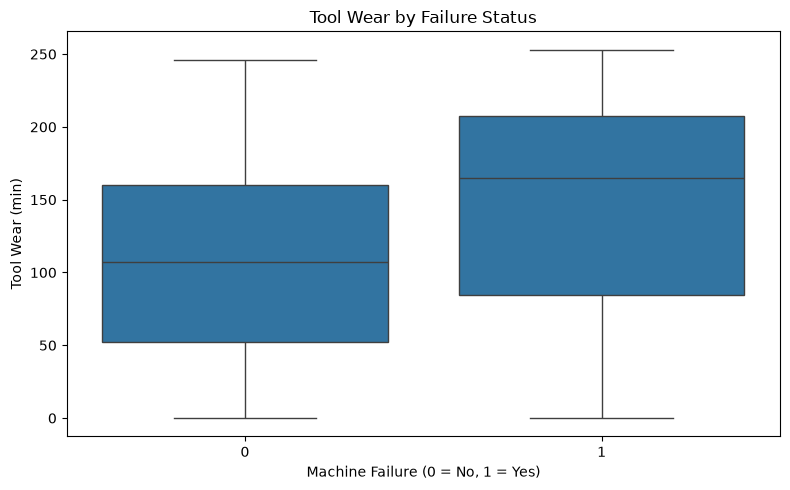

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df,x="Machine failure",y="Tool wear [min]")

plt.title("Tool Wear by Failure Status")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Tool Wear (min)")
plt.tight_layout()
plt.show()

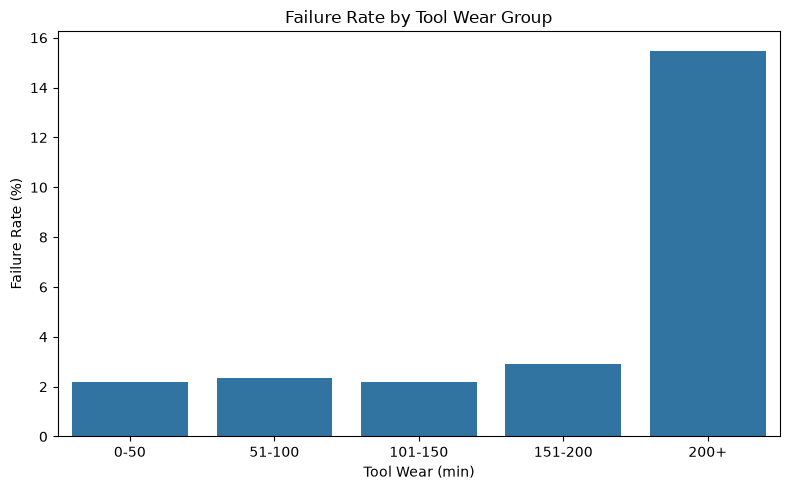

In [28]:
wear_data = df.copy()

wear_data["Wear Group"] = pd.cut(
    wear_data["Tool wear [min]"],
    bins=[-1, 50, 100, 150, 200, float("inf")],
    labels=["0-50", "51-100", "101-150", "151-200", "200+"])

wear_rate = (
    wear_data.groupby("Wear Group", observed=False)["Machine failure"]
    .mean()
    .mul(100)
    .reset_index(name="Failure Rate (%)"))

plt.figure(figsize=(8, 5))

sns.barplot(
    data=wear_rate,
    x="Wear Group",
    y="Failure Rate (%)",
    errorbar=None)

plt.title("Failure Rate by Tool Wear Group")
plt.xlabel("Tool Wear (min)")
plt.ylabel("Failure Rate (%)")
plt.tight_layout()
plt.show()

## 8. Predictive Maintenance Model
## ML
### Modeling objective

Predict:

`Machine failure = 0` → no recorded failure

`Machine failure = 1` → recorded failure



In [29]:
X=df_fe.drop(columns=['Machine failure','TWF','HDF','PWF','OSF','RNF'])
y=df_fe['Machine failure']

print("Features Shape:",X.shape)
print("Target Shape:",y.shape)

X.head()

Features Shape: (10000, 10)
Target Shape: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temp_Diff,Power,Wear_Torque_Ratio,Wear_Speed_Interaction
0,1,-0.952389,-0.947360,0.068185,0.282200,-1.695984,0.498849,0.629443,-1.526544,-1.651974
1,0,-0.902393,-0.879959,-0.729472,0.633308,-1.648852,0.498849,0.512456,-1.477401,-1.609967
2,0,-0.952389,-1.014761,-0.227450,0.944290,-1.617430,0.398954,1.376889,-1.439155,-1.577488
3,0,-0.902393,-0.947360,-0.590021,-0.048845,-1.586009,0.398954,-0.330009,-1.428717,-1.552218
4,0,-0.902393,-0.879959,-0.729472,0.001313,-1.554588,0.498849,-0.357824,-1.399175,-1.525954


In [30]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("X_train:",X_train.shape)
print("X_test:",X_test.shape)

print("y_train:",y_train.shape)
print("y_test:",y_test.shape)

X_train: (8000, 10)
X_test: (2000, 10)
y_train: (8000,)
y_test: (2000,)


In [31]:
numerical_features=X_train.select_dtypes(include=['int64','float64']).columns
categorical_features=['Type']

preprocessor=ColumnTransformer(transformers=[('num',StandardScaler(),numerical_features),('cat',OneHotEncoder(handle_unknown='ignore'),categorical_features)])

print("Numerical Features:",list(numerical_features))
print("Categorical Features:",categorical_features)

Numerical Features: ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temp_Diff', 'Power', 'Wear_Torque_Ratio', 'Wear_Speed_Interaction']
Categorical Features: ['Type']


In [32]:
lr_model=Pipeline(steps=[('preprocessor', preprocessor),('classifier', LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42))])
lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Type','Air temperature [K]','Process temperature [K]',...,'Power', 'Wear_Torque_Ratio','Wear_Speed_Interaction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

In [33]:
y_pred_lr=lr_model.predict(X_test)
print("First 20 Predictions:")
print(y_pred_lr[:20])

First 20 Predictions:
[1 0 1 0 1 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0]


In [34]:
print("Accuracy:",accuracy_score(y_test,y_pred_lr))
print("Precision:",precision_score(y_test,y_pred_lr,zero_division=0))
print("Recall:",recall_score(y_test,y_pred_lr,zero_division=0))
print("F1 Score:",f1_score(y_test,y_pred_lr,zero_division=0))
print("\nClassification Report:")
print(classification_report(y_test,y_pred_lr,zero_division=0))

Accuracy: 0.86
Precision: 0.18072289156626506
Recall: 0.8823529411764706
F1 Score: 0.3

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.86      0.92      1932
           1       0.18      0.88      0.30        68

    accuracy                           0.86      2000
   macro avg       0.59      0.87      0.61      2000
weighted avg       0.97      0.86      0.90      2000



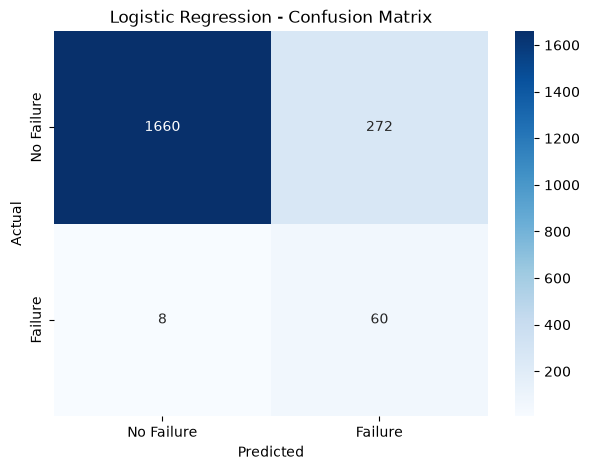

In [35]:
cm=confusion_matrix(y_test,y_pred_lr)
plt.figure(figsize=(7,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['No Failure','Failure'],yticklabels=['No Failure','Failure'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

In [36]:
dt_model=Pipeline(steps=[('preprocessor',preprocessor),('classifier',DecisionTreeClassifier(max_depth=5,class_weight='balanced',random_state=42))])
dt_model.fit(X_train,y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [37]:
y_pred_dt = dt_model.predict(X_test)

print("Decision Tree Results:\n")
print("Accuracy:",accuracy_score(y_test,y_pred_dt))
print("Precision:",precision_score(y_test,y_pred_dt,zero_division=0))
print("Recall:",recall_score(y_test,y_pred_dt,zero_division=0))
print("F1 Score:",f1_score(y_test,y_pred_dt,zero_division=0))
print("\nClassification Report:")
print(classification_report(y_test,y_pred_dt,zero_division=0))

Decision Tree Results:

Accuracy: 0.9455
Precision: 0.36942675159235666
Recall: 0.8529411764705882
F1 Score: 0.5155555555555555

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1932
           1       0.37      0.85      0.52        68

    accuracy                           0.95      2000
   macro avg       0.68      0.90      0.74      2000
weighted avg       0.97      0.95      0.96      2000



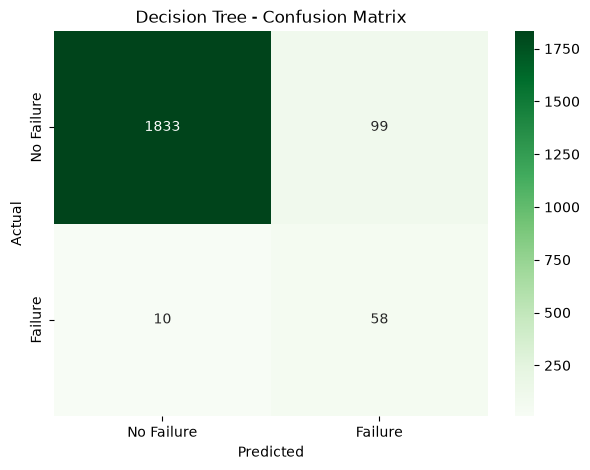

In [38]:
cm_dt=confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7,5))
sns.heatmap(cm_dt,annot=True,fmt='d',cmap='Greens',xticklabels=['No Failure','Failure'],yticklabels=['No Failure','Failure'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Decision Tree - Confusion Matrix')
plt.show()

In [39]:
rf_model=Pipeline(steps=[('preprocessor', preprocessor),('classifier', RandomForestClassifier(n_estimators=200,max_depth=10,class_weight='balanced',random_state=42,n_jobs=-1))])
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [40]:
y_pred_rf=rf_model.predict(X_test)

print("Random Forest Results:\n")
print("Accuracy:",accuracy_score(y_test,y_pred_rf))
print("Precision:",precision_score(y_test,y_pred_rf,zero_division=0))
print("Recall:",recall_score(y_test,y_pred_rf,zero_division=0))
print("F1 Score:",f1_score(y_test,y_pred_rf,zero_division=0))
print("\nClassification Report:")
print(classification_report(y_test,y_pred_rf,zero_division=0))

Random Forest Results:

Accuracy: 0.981
Precision: 0.6829268292682927
Recall: 0.8235294117647058
F1 Score: 0.7466666666666667

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.68      0.82      0.75        68

    accuracy                           0.98      2000
   macro avg       0.84      0.91      0.87      2000
weighted avg       0.98      0.98      0.98      2000



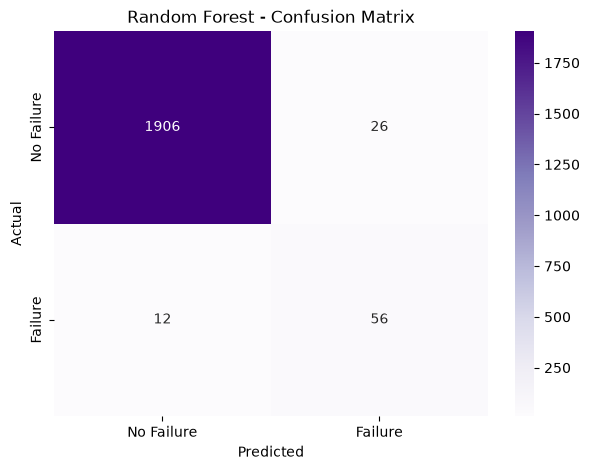

In [41]:
cm_rf=confusion_matrix(y_test,y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(cm_rf,annot=True,fmt='d',cmap='Purples',xticklabels=['No Failure','Failure'],yticklabels=['No Failure','Failure'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest - Confusion Matrix')
plt.show()

In [42]:
models={'Logistic Regression':y_pred_lr,'Decision Tree':y_pred_dt,'Random Forest':y_pred_rf}
results = []
for name,predictions in models.items():
    results.append({
        'Model':name,
        'Accuracy':accuracy_score(y_test,predictions),
        'Precision':precision_score(y_test,predictions,zero_division=0),
        'Recall':recall_score(y_test,predictions,zero_division=0),
        'F1 Score':f1_score(y_test,predictions,zero_division=0)
        })
comparison_df=pd.DataFrame(results)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8600,0.1807,0.8824,0.3000
1,Decision Tree,0.9455,0.3694,0.8529,0.5156
2,Random Forest,0.9810,0.6829,0.8235,0.7467


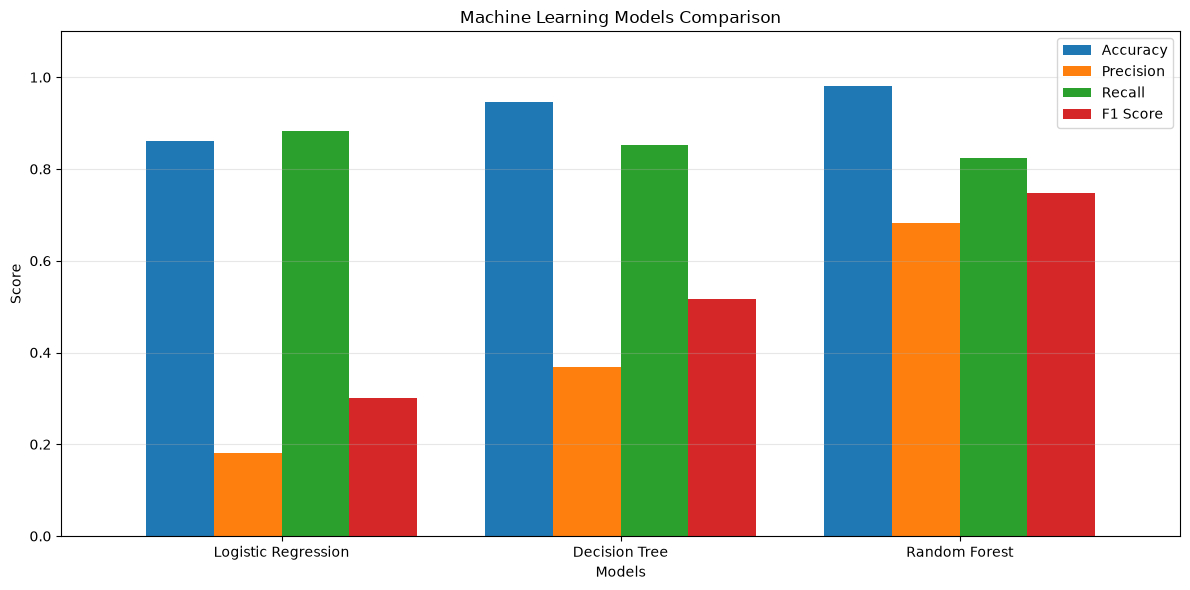

In [43]:
comparison_df.set_index('Model').plot(kind='bar',figsize=(12,6),width=0.8)

plt.title('Machine Learning Models Comparison')
plt.ylabel('Score')
plt.xlabel('Models')
plt.ylim(0,1.1)
plt.xticks(rotation=0)
plt.legend(loc='upper right')
plt.grid(axis='y',alpha=0.3)
plt.tight_layout()
plt.show()

In [44]:
param_grid={
    'classifier__n_estimators':[100,200,300],
    'classifier__max_depth':[5,10,15,None],
    'classifier__min_samples_split':[2,5,10],
    'classifier__min_samples_leaf':[1,2,4],
    'classifier__class_weight':['balanced','balanced_subsample']
}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
random_search=RandomizedSearchCV(estimator=rf_model,param_distributions=param_grid,n_iter=20,scoring='f1',cv=cv,verbose=1,random_state=42,n_jobs=1,error_score='raise')
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__class_weight': ['balanced', 'balanced_subsample'], 'classifier__max_depth': [5, 10, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"re

In [45]:
print("Best Parameters:\n",random_search.best_params_)
print("\nBest Cross-Validation F1 Score:\n",random_search.best_score_)

Best Parameters:
 {'classifier__n_estimators': 100, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_depth': 15, 'classifier__class_weight': 'balanced_subsample'}

Best Cross-Validation F1 Score:
 0.8638536179221502


In [46]:
best_rf_model = random_search.best_estimator_
y_pred_rf_tuned = best_rf_model.predict(X_test)

print("Tuned Random Forest Results:\n")
print("Accuracy:",accuracy_score(y_test,y_pred_rf_tuned))
print("Precision:",precision_score(y_test,y_pred_rf_tuned,zero_division=0))
print("Recall:",recall_score(y_test,y_pred_rf_tuned,zero_division=0))
print("F1 Score:",f1_score(y_test,y_pred_rf_tuned,zero_division=0))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_tuned, zero_division=0))

Tuned Random Forest Results:

Accuracy: 0.9895
Precision: 0.8852459016393442
Recall: 0.7941176470588235
F1 Score: 0.8372093023255814

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.89      0.79      0.84        68

    accuracy                           0.99      2000
   macro avg       0.94      0.90      0.92      2000
weighted avg       0.99      0.99      0.99      2000



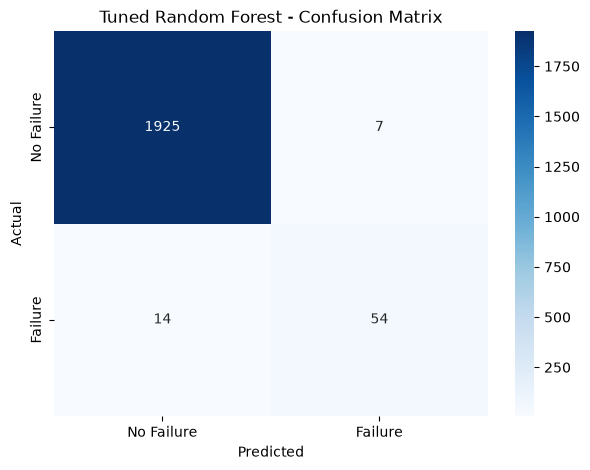

In [47]:
cm_rf_tuned=confusion_matrix(y_test,y_pred_rf_tuned)

plt.figure(figsize=(7,5))
sns.heatmap(cm_rf_tuned,annot=True,fmt='d',cmap='Blues',xticklabels=['No Failure','Failure'],yticklabels=['No Failure','Failure'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Random Forest - Confusion Matrix')
plt.show()

In [48]:
rf_classifier=best_rf_model.named_steps['classifier']
feature_names=best_rf_model.named_steps['preprocessor'].get_feature_names_out()
importances=rf_classifier.feature_importances_
feature_importance_df=pd.DataFrame({'Feature':feature_names,'Importance':importances})
feature_importance_df=feature_importance_df.sort_values(by='Importance',ascending=False)
display(feature_importance_df)

,Feature,Importance
3,num__Rotational speed [rpm],0.200278
4,num__Torque [Nm],0.187060
7,num__Power,0.163698
5,num__Tool wear [min],0.116171
8,num__Wear_Torque_Ratio,0.095999
6,num__Temp_Diff,0.094377
9,num__Wear_Speed_Interaction,0.060696
1,num__Air temperature [K],0.046855
2,num__Process temperature [K],0.024636
10,cat__Type_0,0.003433


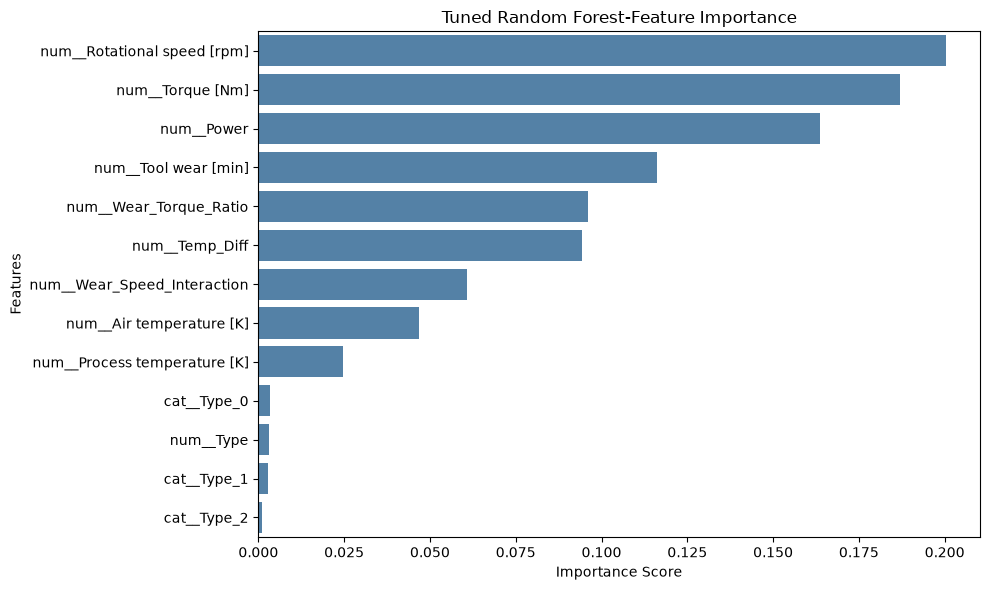

In [49]:
plt.figure(figsize=(10,6))
sns.barplot(data=feature_importance_df,x='Importance',y='Feature',color='steelblue')
plt.title('Tuned Random Forest-Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [ ]:
final_model=best_rf_model
new_machine=pd.DataFrame({'Type':['L'],'Air temperature [K]':[300.5],'Process temperature [K]':[310.2],'Rotational speed [rpm]':[1400],'Torque [Nm]':[55.0],'Tool wear [min]':[180]})

new_machine['Temp_Diff'] = new_machine['Process temperature [K]'] - new_machine['Air temperature [K]']
new_machine['Power'] = new_machine['Rotational speed [rpm]'] * new_machine['Torque [Nm]']
new_machine['Wear_Torque_Ratio'] = new_machine['Tool wear [min]'] * new_machine['Torque [Nm]']
new_machine['Wear_Speed_Interaction'] = new_machine['Tool wear [min]'] * new_machine['Rotational speed [rpm]']
new_machine['Type'] = new_machine['Type'].map({'L': 0, 'M': 1, 'H': 2})
new_machine[features_to_scale] = scaler.transform(new_machine[features_to_scale])
new_machine = new_machine[X_train.columns]

prediction=final_model.predict(new_machine)
probability = final_model.predict_proba(new_machine)[0][1]

print("Machine Failure Prediction:",prediction[0])
print(f"Estimated Failure Probability:{probability:.2%}")

if prediction[0]==1:
    print("Warning: Potential Machine Failure!")
else:
    print("Machine Operating Normally")


Machine Failure Prediction: 0
Estimated Failure Probability:2.63%
Machine Operating Normally


In [51]:
joblib.dump(final_model, 'predictive_maintenance_model.pkl')
loaded_model = joblib.load('predictive_maintenance_model.pkl')
loaded_prediction = loaded_model.predict(new_machine)

## 9. Limitations

- The dataset represents a specific industrial setting and may not generalize to every factory.
- The target is a recorded failure label, not necessarily a precise "time until failure".
- Failure events are relatively rare, so accuracy alone is not sufficient.
- Sensor relationships are observational; correlation does not prove physical causation.
- The dataset does not include maintenance cost, downtime duration, or repair duration.
- Some failure-mode columns directly describe the target and therefore cannot be used as predictive inputs.
- The dataset does not contain vibration measurements, so vibration-specific conclusions cannot be made.
- A real deployment would require chronological validation and monitoring for data drift.

## 10. Dashboard



In [52]:
BG = "#0B1120"
PANEL = "#151F32"
TEXT = "#F1F5F9"
MUTED = "#94A3B8"
CYAN = "#22D3EE"
PURPLE = "#A78BFA"
GREEN = "#34D399"
RED = "#FB7185"
YELLOW = "#FBBF24"

required_columns = ["Type","Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]","Machine failure"]

missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}\n""Check that you loaded the original AI4I dataset.")

numeric_columns = ["Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]","Machine failure"]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=required_columns).copy()

df = df[df["Machine failure"].isin([0, 1])].copy()
df["Machine failure"] = df["Machine failure"].astype(int)

def style_fig(fig, height=380):
    fig.update_layout(template="plotly_dark",paper_bgcolor=BG,plot_bgcolor=PANEL,font=dict(family="Arial", color=TEXT, size=12),title_font=dict(size=16, color=TEXT),margin=dict(l=40, r=25, t=65, b=45),height=height,legend=dict( bgcolor="rgba(0,0,0,0)",font=dict(color=TEXT)),hoverlabel=dict(bgcolor="#1E293B",font_color=TEXT))
    fig.update_xaxes(gridcolor="#263449")
    fig.update_yaxes(gridcolor="#263449")
    return fig

display(HTML(f"""
<div style="
    background:linear-gradient(120deg,#111827,#172554,#164E63);
    padding:28px;
    border-radius:16px;
    font-family:Arial;
    margin-bottom:18px;
">
    <p style="color:{CYAN};letter-spacing:3px;font-size:12px;">
        INDUSTRIAL INTELLIGENCE CENTER
    </p>
    <h1 style="color:{TEXT};margin:8px 0;">
        ⚙️ Predictive Maintenance Dashboard
    </h1>
    <p style="color:{MUTED};margin:0;">
        AI4I 2020 | Machine Health & Failure Analytics
    </p>
</div>
"""))

def create_dashboard(machine="All", max_wear=None):
    data = df.copy()
    if machine != "All":
        data = data[data["Type"] == machine]
    if max_wear is not None:
        data = data[data["Tool wear [min]"] <= max_wear]
    if data.empty:
        display(HTML(
            f"<h3 style='color:{RED}'>"
            "No records match the selected filters."
            "</h3>"))
        return

    total = len(data)
    failures = int(data["Machine failure"].sum())
    no_failure = total - failures
    failure_rate = failures / total * 100

    def kpi(title, value, note, color):
        return f"""
        <div style="
            flex:1;
            min-width:150px;
            padding:18px;
            background:{PANEL};
            border:1px solid #263449;
            border-left:4px solid {color};
            border-radius:12px;
            font-family:Arial;
        ">
            <div style="color:{MUTED};font-size:12px;">
                {title}
            </div>
            <div style="
                color:{color};
                font-size:28px;
                font-weight:bold;
                margin:10px 0;
            ">{value}</div>
            <div style="color:{MUTED};font-size:11px;">
                {note}
            </div>
        </div>
        """

    display(HTML(f"""
    <div style="display:flex;flex-wrap:wrap;gap:12px;
                margin:12px 0 24px;">
        {kpi("TOTAL RECORDS", f"{total:,}",
             "Filtered observations", CYAN)}
        {kpi("MACHINE FAILURES", f"{failures:,}",
             "Recorded failures", RED)}
        {kpi("FAILURE RATE", f"{failure_rate:.2f}%",
             "Failure / total records", YELLOW)}
        {kpi("NO RECORDED FAILURE", f"{no_failure:,}",
             "Machine failure = 0", GREEN)}
    </div>
    """))

    data["Failure Status"] = data["Machine failure"].map({
        0: "No Failure",
        1: "Failure"})

    failure_counts = (data["Failure Status"].value_counts().reindex(["No Failure", "Failure"], fill_value=0).rename_axis("Status").reset_index(name="Count"))

    fig1 = px.pie(failure_counts,names="Status",values="Count",hole=0.68,color="Status",color_discrete_map={"No Failure": GREEN,"Failure": RED},
        title="Machine Failure Distribution")

    fig1.update_traces(
        textinfo="percent+label",
        hovertemplate=(
            "%{label}<br>Records: %{value:,}"
            "<br>Share: %{percent}<extra></extra>"))

    fig1.add_annotation(
        text=f"{failure_rate:.2f}%<br>Failure Rate",
        x=0.5, y=0.5,
        showarrow=False,
        font=dict(size=17, color=TEXT))

    style_fig(fig1)

    type_stats = (data.groupby("Type", observed=True).agg(Records=("Machine failure", "size"),Failures=("Machine failure", "sum"))
        .reset_index())
    type_stats["Failure Rate (%)"] = (
        type_stats["Failures"] / type_stats["Records"] * 100)

    fig2 = px.bar(
        type_stats,
        x="Type",
        y="Failure Rate (%)",
        color="Type",
        text=type_stats["Failure Rate (%)"].map(
            lambda x: f"{x:.2f}%"),
        hover_data=["Records", "Failures"],
        title="Failure Rate by Machine Type",
        color_discrete_sequence=[CYAN, PURPLE, YELLOW])

    fig2.update_traces(textposition="outside")
    style_fig(fig2)

    scatter_data = data
    if len(scatter_data) > 4000:
        scatter_data = scatter_data.sample(4000, random_state=42)

    fig3 = px.scatter(
        scatter_data,
        x="Rotational speed [rpm]",
        y="Torque [Nm]",
        color="Failure Status",
        hover_data=["Type","Tool wear [min]","Air temperature [K]","Process temperature [K]"],
        color_discrete_map={"No Failure": CYAN,"Failure": RED},
        opacity=0.75,
        title="Torque vs Rotational Speed")
    style_fig(fig3)

    fig4 = px.histogram(data,x="Tool wear [min]",color="Failure Status",
        nbins=30,
        barmode="overlay",
        opacity=0.78,
        color_discrete_map={"No Failure": CYAN,"Failure": RED},
        title="Tool Wear Distribution")
    style_fig(fig4)

    mode_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]
    available_modes = [col for col in mode_columns if col in data.columns]

    if available_modes:
        mode_counts = pd.DataFrame({
            "Failure Mode": available_modes,
            "Occurrences": [
                pd.to_numeric(data[col], errors="coerce")
                .fillna(0).sum()
                for col in available_modes]}).sort_values("Occurrences", ascending=True)

        fig5 = px.bar(
            mode_counts,
            x="Occurrences",
            y="Failure Mode",
            orientation="h",
            text="Occurrences",
            color="Occurrences",
            color_continuous_scale=["#164E63", CYAN, PURPLE],
            title="Failure Mode Flags")

        fig5.update_traces(textposition="outside")
        fig5.update_layout(coloraxis_showscale=False)
        style_fig(fig5)
    else:
        fig5 = go.Figure()
        fig5.add_annotation(
            text="Failure mode columns are not available",
            showarrow=False)
        style_fig(fig5)

    fig6 = px.scatter(
        scatter_data,
        x="Air temperature [K]",
        y="Process temperature [K]",
        color="Failure Status",
        hover_data=["Type", "Tool wear [min]"],
        color_discrete_map={"No Failure": CYAN,"Failure": RED},
        opacity=0.75,
        title="Air Temperature vs Process Temperature")
    style_fig(fig6)

    sensor_columns = ["Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]","Machine failure"]
    corr = data[sensor_columns].corr()

    fig7 = px.imshow(
        corr,text_auto=".2f",aspect="auto",color_continuous_scale="RdBu_r",zmin=-1,zmax=1,title="Sensor Correlation Matrix")
    style_fig(fig7, height=450)

    for fig in [fig1, fig2, fig3, fig4, fig5, fig6, fig7]:
        fig.show(config={"displaylogo": False})

    display(HTML(f"""
    <div style="
        background:{PANEL};
        padding:18px;
        border-radius:12px;
        color:{MUTED};
        font-family:Arial;
        margin-top:18px;
    ">
        <h3 style="color:{CYAN};">Analyst Notes</h3>
        <p>
            Results are calculated from the selected records.
            Correlation does not establish causation.
        </p>
        <p>
            Failure mode flags can overlap. Their counts should not
            be added to estimate the total number of failures.
        </p>
        <p>
            This dashboard analyzes recorded observations; it does not
            represent live monitoring or predict future failures.
        </p>
    </div>
    """))

try:
    import ipywidgets as widgets

    machine_filter = widgets.Dropdown(
        options=["All"] + sorted(df["Type"].dropna().unique().tolist()),
        value="All",
        description="Machine Type:")

    wear_filter = widgets.IntSlider(
        value=int(df["Tool wear [min]"].max()),
        min=0,
        max=max(1, int(df["Tool wear [min]"].max())),
        step=1,
        description="Max Tool Wear:",
        continuous_update=False,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="400px"))

    output = widgets.interactive_output(
        create_dashboard,
        {"machine": machine_filter,"max_wear": wear_filter})

    display(widgets.HBox(
        [machine_filter, wear_filter],
        layout=widgets.Layout(flex_flow="row wrap", gap="15px")))
    display(output)

except (ImportError, ModuleNotFoundError):
    print(
        "ipywidgets is unavailable. Displaying the dashboard "
        "without notebook filters.")
    create_dashboard()

Output()